In [1]:
# Local setup: select the torch3_clean Python environment as the notebook kernel.
# No code/data downloads or automatic package installations are performed.
import os
import sys
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

# Works when the notebook kernel starts in pcb/ or the repository root.
code_candidates = [Path.cwd(), Path.cwd() / "pcb"]
CODE_DIR = next((p.resolve() for p in code_candidates
                 if (p / "nn_unet.py").is_file() and (p / "dataset.py").is_file()), None)
if CODE_DIR is None:
    raise FileNotFoundError("Start the notebook from pcb/ or the Surrogates repository root.")
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

# Prefer the dataset beside pcb/, with support for the existing pcb/data/ clone.
# Set PCB_DATA_ROOT to override either location, e.g. for a sample-only check.
data_override = os.environ.get("PCB_DATA_ROOT")
data_candidates = ([Path(data_override)] if data_override else [
    CODE_DIR.parent / "Multi-topology-Dataset",
    CODE_DIR.parent / "data" / "Multi-topology-Dataset",
    CODE_DIR / "data" / "Multi-topology-Dataset",
])
DATA_ROOT = next((p.resolve() for p in data_candidates
                  if all((p / split).is_dir() for split in ("TrainData", "ValData"))), None)
if DATA_ROOT is None:
    raise FileNotFoundError(f"Expected TrainData/ValData under one of: {data_candidates}")

WORKING_DIR = Path(os.environ.get("PCB_WORKING_DIR", str(CODE_DIR / "outputs" / "patch_context_investigation_1000pairs_resenc_wide")))
WORKING_DIR.mkdir(parents=True, exist_ok=True)
SMOKE_TEST = os.environ.get("PCB_SMOKE_TEST", "0") == "1"

requirements = {"nnunetv2": "2.7.0", "dynamic-network-architectures": "0.4.3"}
try:
    installed = {name: version(name) for name in requirements}
except PackageNotFoundError as exc:
    raise ModuleNotFoundError(
        "Select torch3_clean, or install the dependencies in the current kernel with "
        "%pip install nnunetv2==2.7.0 dynamic-network-architectures==0.4.3 h5py pandas matplotlib"
    ) from exc
print("Python:", sys.executable)
print("Local code:", CODE_DIR)
print("Local dataset:", DATA_ROOT)
print("Outputs:", WORKING_DIR)
print("External packages:", installed)
print("Smoke-test configuration:", SMOKE_TEST)


Python: <user-profile>\AppData\Local\miniconda3\envs\torch3_clean\python.exe
Local code: pcb
Local dataset: pcb\data\Multi-topology-Dataset
Outputs: pcb\outputs\patch_context_investigation_1000pairs_resenc_wide
External packages: {'nnunetv2': '2.7.0', 'dynamic-network-architectures': '0.4.3'}
Smoke-test configuration: False


In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from pathlib import Path
import json
import time
from dataset import PCBDataset, NormalizationStats
from nn_unet import NNUNetRegressor, PCBImageDataset
from patch_context_experiment import (
    build_matched_subset, split_pairs, MatchedPatchDataset, plot_pair, read_case,
)
from IPython.display import display
from importlib.metadata import version
PACKAGE_VERSIONS = {name: version(name) for name in ("nnunetv2", "dynamic-network-architectures")}
print("External packages:", PACKAGE_VERSIONS)

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU
External packages: {'nnunetv2': '2.7.0', 'dynamic-network-architectures': '0.4.3'}


## 1. Hyperparameters

In [3]:
HPARAMS = {
    # controlled subset: TrainData only; multiple matched condition pairs per geometry
    "data_root": str(DATA_ROOT),
    "n_pairs": 1000,  # verified condition pairs, not 1000 distinct layouts
    "pairs_per_layout": 3,  # one pair per layout first, then second/third pairs
    "validation_fraction": 0.2,  # split by distinct geometry
    "max_layouts_to_check": None,  # examine every TrainData layout
    "patch_size": 64,
    "unchanged_margin": 16,  # no changed power within this halo around the patch
    "inspect_pairs": 3,  # only a few detailed previews; overview covers all pairs
    "run_test": False,

    # same external nnU-Net architecture; local inputs only
    "architecture": "resenc",
    "n_blocks_per_stage": [1, 1, 1, 1, 1],  # two main-path convolutions per residual block
    "input_channels": 8,
    "out_channels": 1,
    "features_per_stage": [64, 128, 256, 512, 512],
    "n_conv_per_stage": 2,  # used by plain mode; resenc uses n_blocks_per_stage
    "n_conv_per_stage_decoder": 2,

    # train on both fixed 64x64 targets from every training pair, no augmentation
    "batch_size": 32,
    "epochs": 200,
    "lr": 1e-3,
    "weight_decay": 0.0,
    "max_grad_norm": 0.1,

    # runtime
    "num_workers": 0,
    "pin_memory": True,
    "seed": 42,

    # output
    "checkpoint_path": str(WORKING_DIR / "patch_context.pt"),
    "last_checkpoint_path": str(WORKING_DIR / "patch_context_last.pt"),
    "debug_csv_path": str(WORKING_DIR / "patch_context_debug_log.csv"),
}

DEBUG = {
    "stop_on_nonfinite": True,
    "log_every_n_batches": 20,
    "print_every_n_batches": 20,
    "max_train_batches": None,
    "max_eval_batches": None,
    "detect_anomaly": False,
    "save_parameter_snapshots": True,
}
if SMOKE_TEST:
    HPARAMS.update(features_per_stage=[8, 16, 32], n_blocks_per_stage=[1, 1, 1],
                   epochs=1, batch_size=4, inspect_pairs=2)
    torch.set_num_threads(2)
torch.autograd.set_detect_anomaly(DEBUG["detect_anomaly"])


## 2. Diagnostics

In [4]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def tensor_stats(x):
    x = x.detach()
    finite = torch.isfinite(x)

    out = {
        "finite_fraction": finite.float().mean().item(),
        "nan_count": torch.isnan(x).sum().item(),
        "inf_count": torch.isinf(x).sum().item(),
    }

    if finite.any():
        xf = x[finite].float()
        out.update({
            "mean": xf.mean().item(),
            "std": xf.std(unbiased=False).item(),
            "rms": torch.sqrt(torch.mean(xf * xf)).item(),
            "absmax": xf.abs().max().item(),
            "norm": xf.norm().item(),
            "min": xf.min().item(),
            "max": xf.max().item(),
        })
    else:
        out.update({
            "mean": np.nan, "std": np.nan, "rms": np.nan,
            "absmax": np.nan, "norm": np.nan,
            "min": np.nan, "max": np.nan,
        })

    return out


def check_finite(name, x, context=None):
    if torch.isfinite(x).all():
        return

    context = context or {}
    print("\n" + "=" * 90)
    print("NON-FINITE TENSOR:", name)
    print("context:", context)
    print("shape:", tuple(x.shape))
    print("stats:", tensor_stats(x))
    print("=" * 90)

    if DEBUG["stop_on_nonfinite"]:
        raise FloatingPointError(f"{name} contains NaN/Inf at {context}")


def flatten_finite_tensors(tensors):
    vals = []
    for t in tensors:
        if t is None:
            continue
        a = t.detach().float().reshape(-1).cpu()
        a = a[torch.isfinite(a)]
        if a.numel():
            vals.append(a)
    return torch.cat(vals) if vals else torch.empty(0)


def parameter_group_map(model):
    # Global named_parameters deduplicates upstream decoder/encoder references.
    named = list(model.named_parameters())
    return {
        "input_encoder": [p for name, p in named if name.startswith("network.encoder.stages.0.")],
        "blocks": [p for name, p in named if name.startswith("network.encoder.")
                   and not name.startswith("network.encoder.stages.0.")],
        "decoder": [p for name, p in named if name.startswith("network.decoder.")],
    }


def stats_from_flat(flat):
    if flat.numel() == 0:
        return {
            "mean": np.nan, "std": np.nan, "rms": np.nan,
            "absmax": np.nan, "norm": np.nan,
        }
    return {
        "mean": flat.mean().item(),
        "std": flat.std(unbiased=False).item(),
        "rms": torch.sqrt(torch.mean(flat * flat)).item(),
        "absmax": flat.abs().max().item(),
        "norm": flat.norm().item(),
    }


def group_parameter_stats(params):
    return stats_from_flat(
        flatten_finite_tensors([p.data for p in params])
    )


def group_gradient_stats(params):
    return stats_from_flat(
        flatten_finite_tensors([p.grad for p in params if p.grad is not None])
    )


def snapshot_parameter_values(model):
    return {
        name: flatten_finite_tensors([p.data for p in params]).numpy()
        for name, params in parameter_group_map(model).items()
    }


def snapshot_gradient_values(model):
    return {
        name: flatten_finite_tensors(
            [p.grad for p in params if p.grad is not None]
        ).numpy()
        for name, params in parameter_group_map(model).items()
    }


set_seed(HPARAMS["seed"])

## 3. Build the controlled subset and inspect representative pairs

The selection uses only original `TrainData`. Each pair has the same layout, masks, instance map and cooling, with exactly one changed power-setting parameter. The fixed patch has identical power and other inputs, and no changed power within the configured surrounding margin. The patch location maximizes unchanged locally powered pixels, without ranking by temperature differences. Both members of a pair stay in the same split, with distinct layouts held out for investigation validation. This is an investigation-specific split, not the original ValData/TestData benchmark.

The following cell saves the pair manifest and plots the selected cases **before the model is instantiated**. Inspect the red patch rectangles, external power changes and the two local temperature targets.


Building verified matched simulation pairs...
Examined 25/424 layouts; verified 75 candidate pairs
Examined 50/424 layouts; verified 150 candidate pairs
Examined 75/424 layouts; verified 225 candidate pairs
Examined 100/424 layouts; verified 300 candidate pairs
Examined 125/424 layouts; verified 375 candidate pairs
Examined 150/424 layouts; verified 450 candidate pairs
Examined 175/424 layouts; verified 525 candidate pairs
Examined 200/424 layouts; verified 600 candidate pairs
Examined 225/424 layouts; verified 675 candidate pairs
Examined 250/424 layouts; verified 750 candidate pairs
Examined 275/424 layouts; verified 825 candidate pairs
Examined 300/424 layouts; verified 900 candidate pairs
Examined 325/424 layouts; verified 975 candidate pairs
Examined 350/424 layouts; verified 1050 candidate pairs
Examined 375/424 layouts; verified 1125 candidate pairs
Examined 400/424 layouts; verified 1200 candidate pairs
Selected 1000 verified pairs across 424 geometries


,pair_id,subset,topology,mask_id,h_value,Pigbt_a,Pigbt_b,Pfwd_a,Pfwd_b,row,column,valid_powered_patch_locations,local_inputs_identical,target_difference_rel_l2,unavoidable_worst_case_rel_l2
0,0,val,Mask_3P6P_V1,000,2000,150,150,100,150,141,87,9304,True,0.109320,0.051876
1,1,train,Mask_3P6P_V2,000,2000,150,150,100,150,44,110,11440,True,0.096586,0.046085
2,2,val,Mask_HB_V1,000,2000,150,150,150,200,68,91,6374,True,0.075723,0.036490
3,3,train,Mask_HB_V2,000,2000,150,150,100,150,41,55,8586,True,0.093300,0.044576
4,4,train,Mask_HB_V3-0,000,2000,150,150,100,200,88,119,3683,True,0.252311,0.112080
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,val,Mask_3P6P_V2,024,2000,350,350,100,150,32,35,10235,True,0.054237,0.026405
996,996,train,Mask_HB_V2,029,2000,350,350,100,150,46,140,7896,True,0.064775,0.031394
997,997,train,Mask_HB_V3-0,035,2000,150,350,100,100,8,34,1679,True,0.465438,0.188827
998,998,val,Mask_HB_V3-1,028,2000,350,350,100,150,53,53,7558,True,0.058783,0.028557


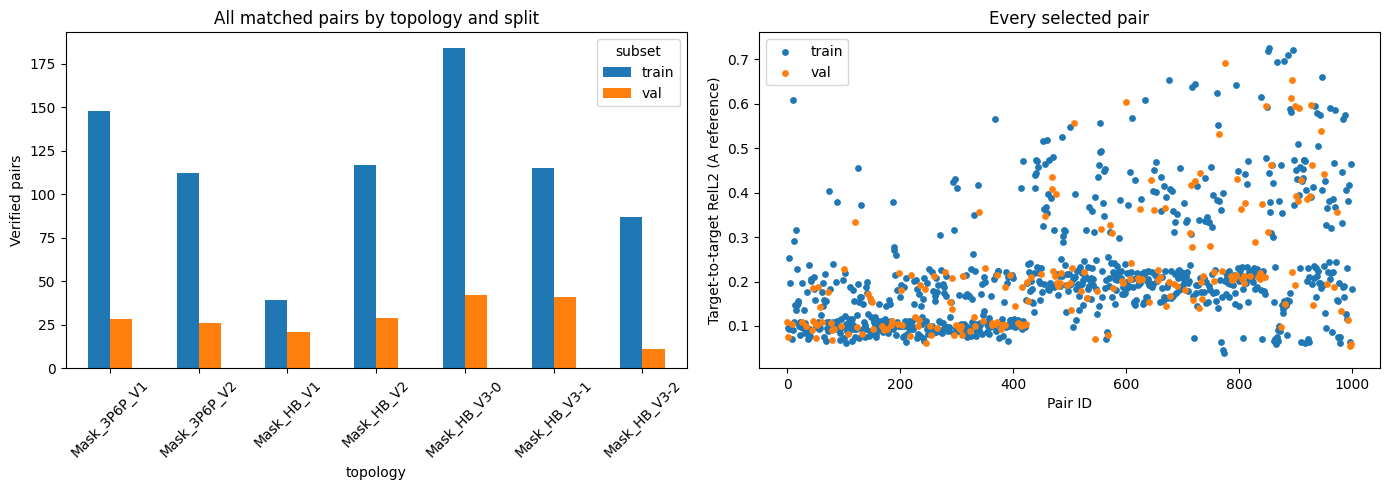

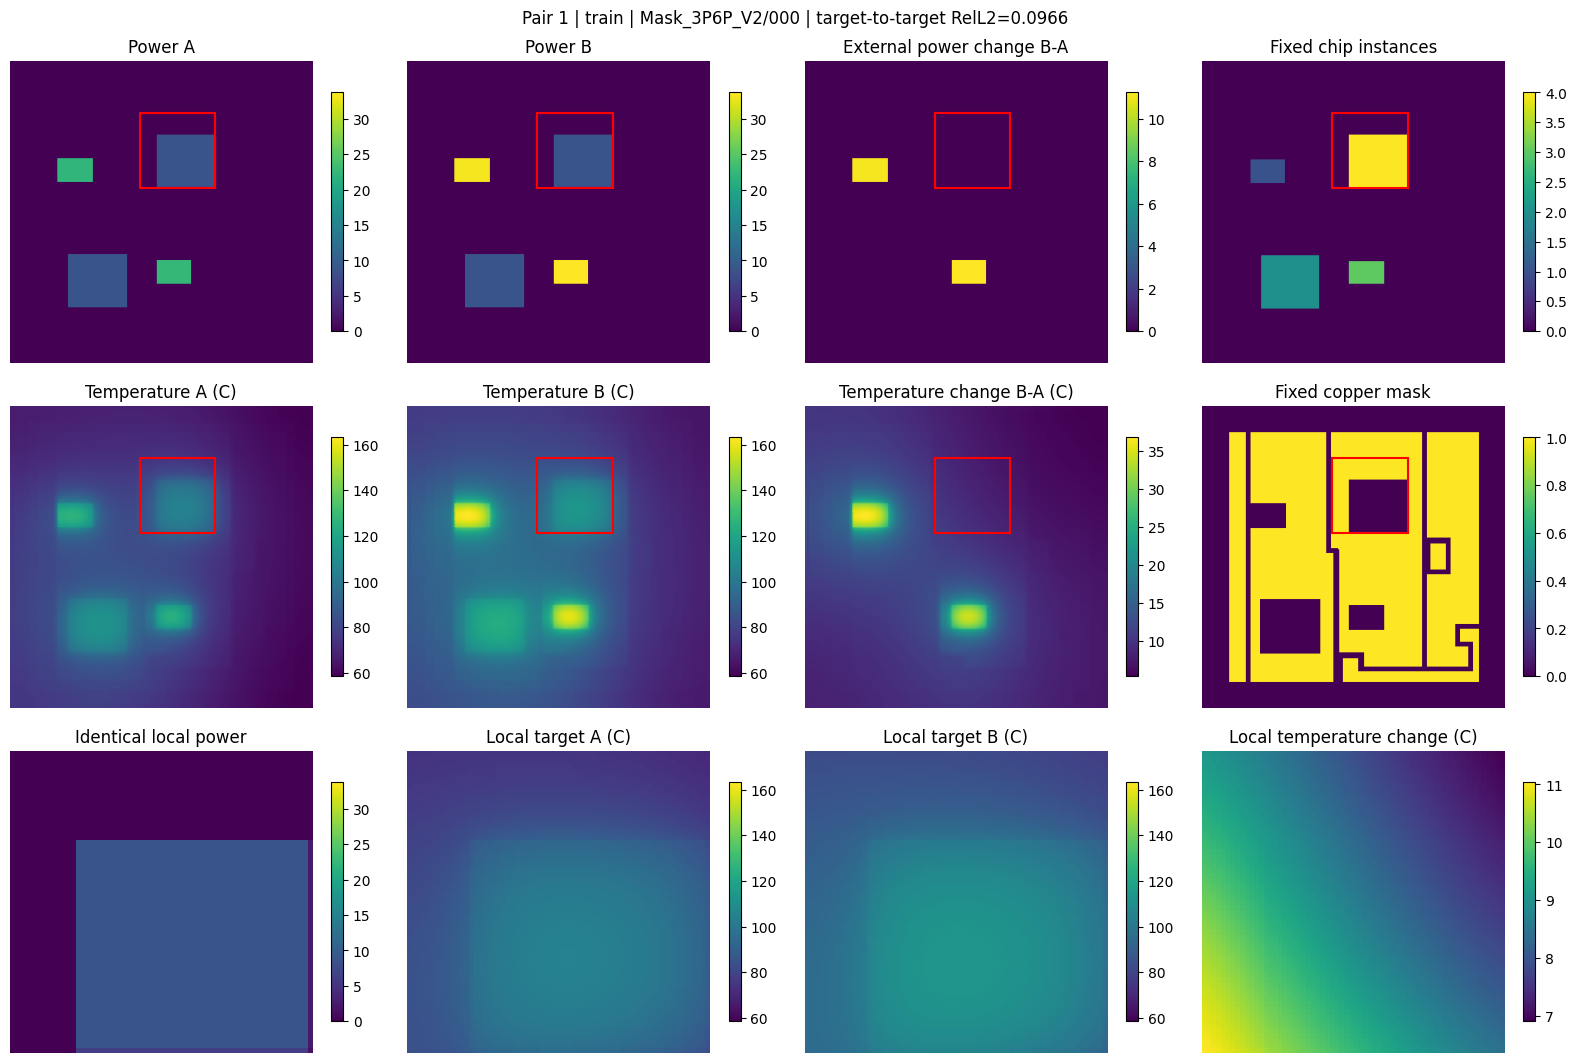

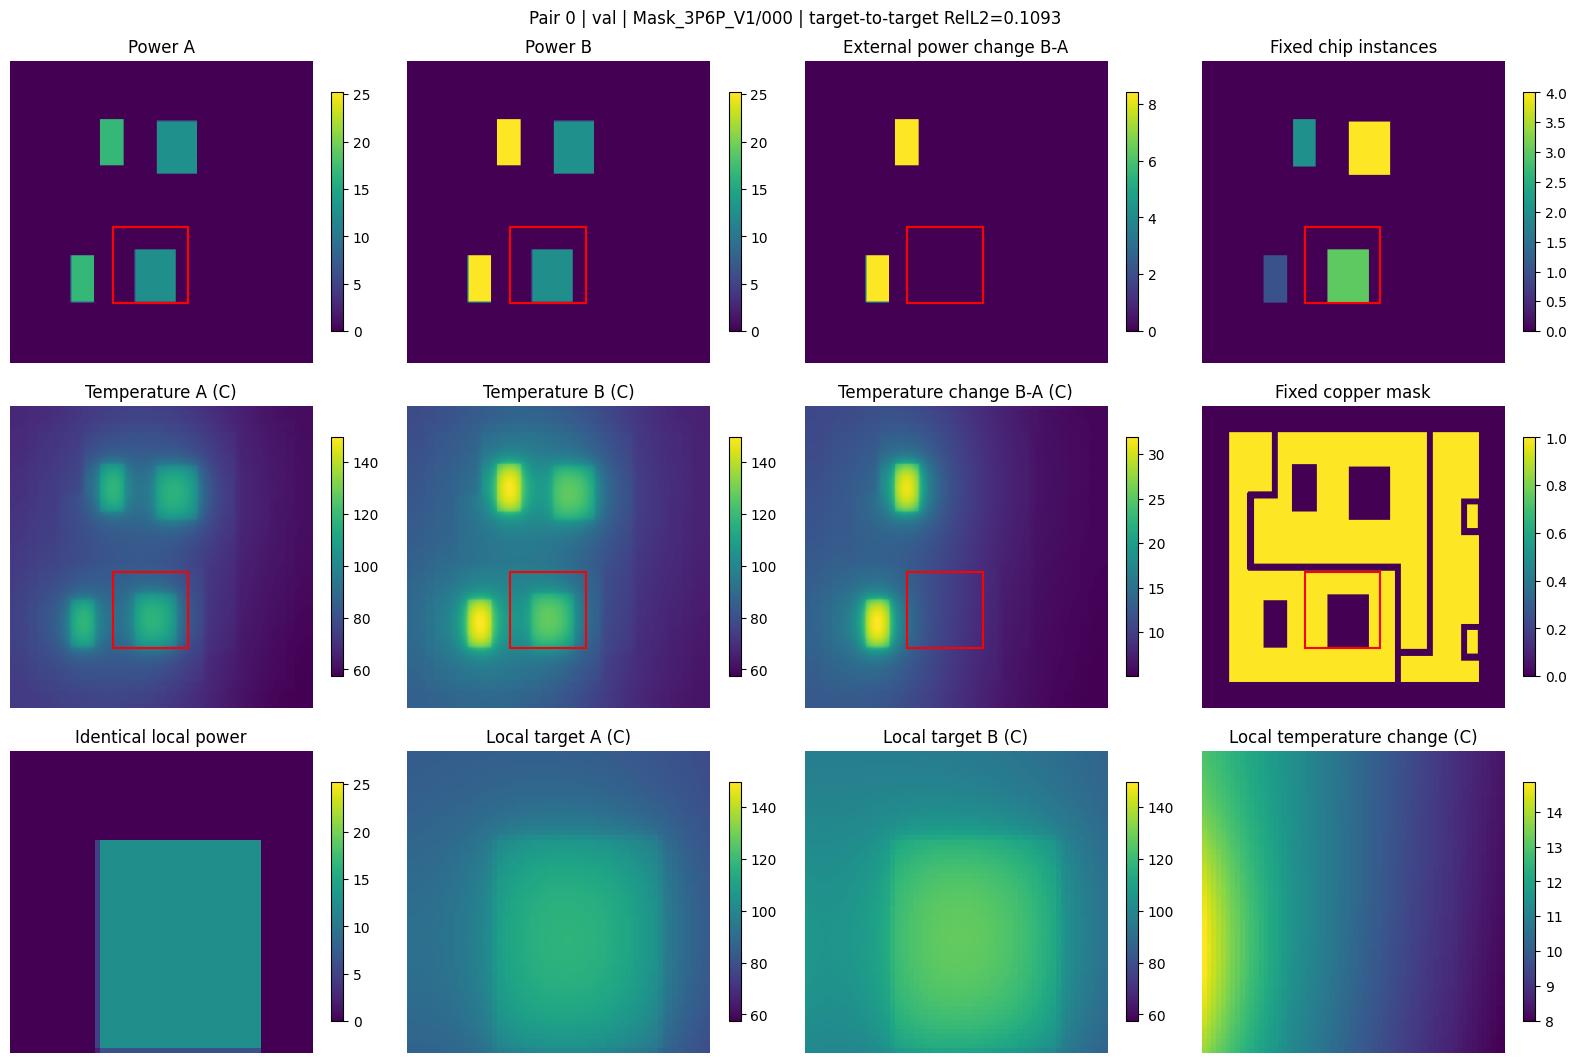

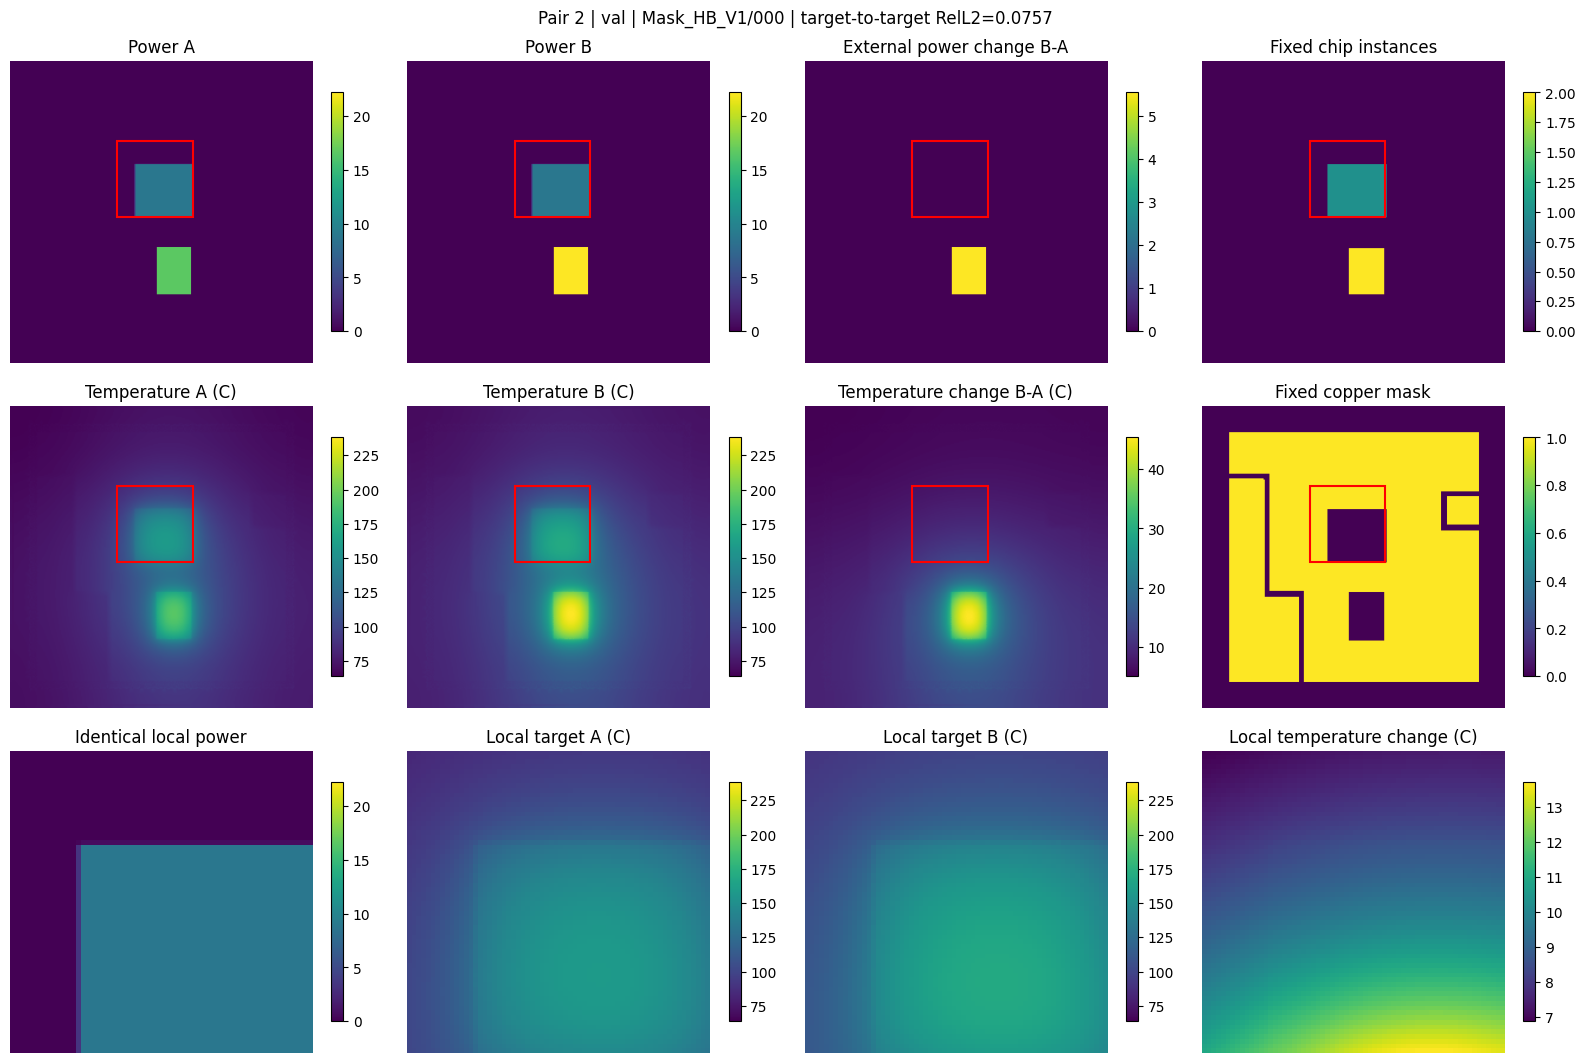

Loaded normalization cache: pcb\outputs\patch_context_investigation_1000pairs_resenc_wide\pcb_normalization.json
Training geometries / pairs / unique patches: 339 802 1371
Validation geometries / pairs / unique patches: 85 198 337
Training batches per epoch: 43
Input / target shapes: [(8, 64, 64), (1, 64, 64)]
All eight normalized input channels match EXACTLY within every pair.
Tests disabled. No random crops, augmentation, global power settings or layout IDs enter the model.


In [5]:
print("Building verified matched simulation pairs...", flush=True)
pairs = build_matched_subset(
    DATA_ROOT, n_pairs=HPARAMS["n_pairs"], patch_size=HPARAMS["patch_size"],
    margin=HPARAMS["unchanged_margin"], max_layouts=HPARAMS["max_layouts_to_check"],
    pairs_per_layout=HPARAMS["pairs_per_layout"],
)
if not 0 < HPARAMS["validation_fraction"] < 1:
    raise ValueError("validation_fraction must be in (0, 1)")
n_geometries = len({r["geometry_hash"] for r in pairs})
n_val_geometries = max(1, min(n_geometries - 1, round(n_geometries * HPARAMS["validation_fraction"])))
pairs = split_pairs(pairs, n_val=n_val_geometries, seed=HPARAMS["seed"])
(WORKING_DIR / "selected_pairs.json").write_text(json.dumps(pairs, indent=2))
pair_table = pd.DataFrame(pairs)
pair_table.to_csv(WORKING_DIR / "selected_pairs.csv", index=False)
display(pair_table[["pair_id", "subset", "topology", "mask_id", "h_value",
                    "Pigbt_a", "Pigbt_b", "Pfwd_a", "Pfwd_b", "row", "column",
                    "valid_powered_patch_locations", "local_inputs_identical",
                    "target_difference_rel_l2", "unavoidable_worst_case_rel_l2"]])

# Summaries cover all verified pairs, not only the detailed previews below.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.crosstab(pair_table["topology"], pair_table["subset"]).plot.bar(ax=axes[0])
axes[0].set_title("All matched pairs by topology and split")
axes[0].set_ylabel("Verified pairs"); axes[0].tick_params(axis="x", labelrotation=45)
for subset in ("train", "val"):
    rows = pair_table[pair_table["subset"] == subset]
    axes[1].scatter(rows["pair_id"], rows["target_difference_rel_l2"], s=15, label=subset)
axes[1].set_xlabel("Pair ID"); axes[1].set_ylabel("Target-to-target RelL2 (A reference)")
axes[1].set_title("Every selected pair"); axes[1].legend()
fig.tight_layout(); fig.savefig(WORKING_DIR / "all_pairs_overview.png", dpi=140)
plt.show(); plt.close(fig)

# Inspection comes before normalization, loaders, model creation and training.
# Include both training and validation in the small preview selection.
preview_order = [next(r for r in pairs if r["subset"] == subset) for subset in ("train", "val")]
preview_order += [r for r in pairs if r["pair_id"] not in {p["pair_id"] for p in preview_order}]
preview_pairs = preview_order[:HPARAMS["inspect_pairs"]]
preview_pair_ids = {r["pair_id"] for r in preview_pairs}
for record in preview_pairs:
    fig = plot_pair(DATA_ROOT, record)
    fig.savefig(WORKING_DIR / f"inspect_pair_{record['pair_id']:02d}.png", dpi=130)
    plt.show()
    plt.close(fig)

train_pairs = [r for r in pairs if r["subset"] == "train"]
val_pairs = [r for r in pairs if r["subset"] == "val"]
assert not ({r["geometry_hash"] for r in train_pairs}
            & {r["geometry_hash"] for r in val_pairs})
train_files = sorted({DATA_ROOT / r[key] for r in train_pairs for key in ("path_a", "path_b")})
normalizer = NormalizationStats.fit(
    train_files, cache_path=WORKING_DIR / "pcb_normalization.json", progress_every=25,
)
train_dataset = MatchedPatchDataset(DATA_ROOT, train_pairs, normalizer)
val_dataset = MatchedPatchDataset(DATA_ROOT, val_pairs, normalizer)
train_loader = DataLoader(train_dataset, batch_size=HPARAMS["batch_size"], shuffle=True,
                          num_workers=HPARAMS["num_workers"], pin_memory=HPARAMS["pin_memory"])
val_loader = DataLoader(val_dataset, batch_size=HPARAMS["batch_size"], shuffle=False,
                        num_workers=HPARAMS["num_workers"], pin_memory=HPARAMS["pin_memory"])
test_dataset = test_loader = None
print("Training geometries / pairs / unique patches:", len({r["geometry_hash"] for r in train_pairs}), len(train_pairs), len(train_dataset))
print("Validation geometries / pairs / unique patches:", len({r["geometry_hash"] for r in val_pairs}), len(val_pairs), len(val_dataset))
print("Training batches per epoch:", len(train_loader))
print("Input / target shapes:", [tuple(t.shape) for t in train_dataset[0]])
print("All eight normalized input channels match EXACTLY within every pair.")
print("Tests disabled. No random crops, augmentation, global power settings or layout IDs enter the model.")


## 4. Debug recorder

In [6]:
class DebugRecorder:
    def __init__(self):
        self.rows = []

    def record_tensor(self, tag, x, context):
        row = dict(context)
        row.update({"kind": "tensor", "tag": tag, **tensor_stats(x)})
        self.rows.append(row)

    def record_scalar(self, tag, value, context):
        row = dict(context)
        row.update({"kind": "scalar", "tag": tag, "value": float(value)})
        self.rows.append(row)

    def dataframe(self):
        return pd.DataFrame(self.rows)


recorder = DebugRecorder()

## 5. nnU-Net and diagnostics hooks

In [7]:
# The U-Net architecture comes from the pip package via nnU-Net's factory.
# Our adapter only reshapes input images and exposes continuous predictions.
diagnostic_context = None
hook_handles = []

def stage_hook(name):
    def hook(module, inputs, output):
        if diagnostic_context is not None:
            check_finite(name, output, diagnostic_context)
            recorder.record_tensor(name, output, diagnostic_context)
    return hook


def predict_field(image):
    # Only the fixed local patch is visible. No extra context from sliding windows.
    return model(image.to(device)).detach().cpu()


## 6. Instantiate model

In [8]:
# Load the exact local file, even if this kernel previously imported an older class.
import importlib.util
model_file = CODE_DIR / "nn_unet.py"
model_spec = importlib.util.spec_from_file_location("pcb_current_nn_unet", model_file)
model_module = importlib.util.module_from_spec(model_spec)
model_spec.loader.exec_module(model_module)
NNUNetRegressor = model_module.NNUNetRegressor
print("Loaded model implementation:", model_file)

# Rerunning this cell replaces the model/optimizer and removes old diagnostic hooks.
for handle in hook_handles:
    handle.remove()
hook_handles = []

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_kwargs = {key: HPARAMS[key] for key in (
    "input_channels", "out_channels", "features_per_stage",
    "n_conv_per_stage", "n_conv_per_stage_decoder", "architecture", "n_blocks_per_stage")}
model = NNUNetRegressor(**model_kwargs).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=HPARAMS["lr"],
                              weight_decay=HPARAMS["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=HPARAMS["epochs"])

for index, stage in enumerate(model.network.encoder.stages):
    hook_handles.append(stage.register_forward_hook(stage_hook(f"encoder.{index}")))
for index, stage in enumerate(model.network.decoder.stages):
    hook_handles.append(stage.register_forward_hook(stage_hook(f"decoder.{index}")))

initial_parameter_snapshot = snapshot_parameter_values(model) if DEBUG["save_parameter_snapshots"] else {}
print("Device:", device)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print(model)


Loaded model implementation: pcb\nn_unet.py
Device: cuda
Parameters: 20769348
NNUNetRegressor(
  (network): ResidualEncoderUNet(
    (encoder): ResidualEncoder(
      (stem): StackedConvBlocks(
        (convs): Sequential(
          (0): ConvDropoutNormReLU(
            (conv): Conv2d(8, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (norm): InstanceNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
            (nonlin): LeakyReLU(negative_slope=0.01, inplace=True)
            (all_modules): Sequential(
              (0): Conv2d(8, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
              (1): InstanceNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
              (2): LeakyReLU(negative_slope=0.01, inplace=True)
            )
          )
        )
      )
      (stages): Sequential(
        (0): StackedResidualBlocks(
          (blocks): Sequential(
            (0): BasicBlockD(
              (conv1): Co

## 7. Loss and metric

In [9]:
def relative_l2_per_sample(pred, target):
    B = pred.shape[0]

    pred = pred.reshape(B, -1)
    target = target.reshape(B, -1)

    diff_norm = torch.norm(
        pred - target,
        p=2,
        dim=1,
    )

    target_norm = torch.norm(
        target,
        p=2,
        dim=1,
    )

    return diff_norm / target_norm


def relative_l2_loss(pred, target):
    return relative_l2_per_sample(
        pred,
        target,
    ).sum()


def mae_metric(pred, target):
    return torch.mean(
        torch.abs(pred - target)
    )

class RelativeL2Stats:
    """Exact distribution of the same per-sample RelL2 used by the epoch mean.

    One value per training patch/image or reconstructed validation image.
    Ratios are dimensionless: 0.1 corresponds to 10%, not degrees Celsius.
    """
    def __init__(self):
        self.values = []

    def __enter__(self):
        return self

    def update(self, prediction, target):
        ratios = relative_l2_per_sample(prediction.detach(), target.detach()).float().cpu().numpy()
        if not np.isfinite(ratios).all():
            raise FloatingPointError("Nonfinite per-sample relative L2 errors")
        self.values.append(ratios.copy())

    def result(self):
        if not self.values:
            raise ValueError("No relative L2 errors recorded")
        values = np.concatenate(self.values)
        quantiles = np.percentile(values, [50, 90, 95, 99])
        return dict(zip(
            ("max_rel_l2", "median_rel_l2", "p90_rel_l2", "p95_rel_l2", "p99_rel_l2"),
            [float(values.max()), *map(float, quantiles)],
        ))

    def __exit__(self, *exc):
        self.values.clear()


## 8. Dry run — inspect matched-patch predictions before training

Fixed matched-patch prediction: (32, 1, 64, 64) {'finite_fraction': 1.0, 'nan_count': 0, 'inf_count': 0, 'mean': 130.5147705078125, 'std': 24.64323616027832, 'rms': 132.82090759277344, 'absmax': 263.2843322753906, 'norm': 48086.32421875, 'min': 30.7064208984375, 'max': 263.2843322753906}
Relative L2: 10.728336334228516
MAE (C): 30.074913024902344


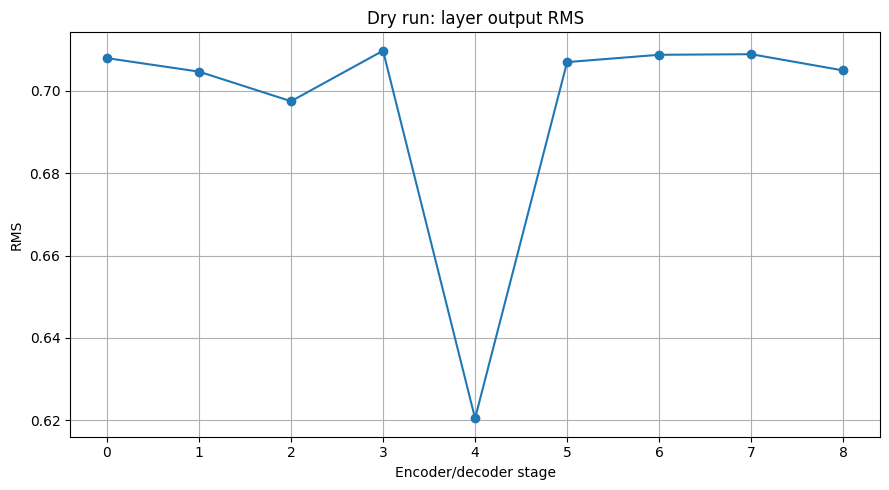

In [10]:
model.eval()
image, target_norm = next(iter(val_loader))
diagnostic_context = {"epoch": 0, "batch": 0, "phase": "dry_run"}
with torch.no_grad():
    pred_norm = predict_field(image)
    pred = normalizer.decode_temperature(pred_norm)
    target = normalizer.decode_temperature(target_norm)
    check_finite("dry_run.prediction", pred, diagnostic_context)
    print("Fixed matched-patch prediction:", tuple(pred.shape), tensor_stats(pred))
    print("Relative L2:", relative_l2_loss(pred, target).item())
    print("MAE (C):", mae_metric(pred, target).item())
diagnostic_context = None
state_rows = recorder.dataframe()
state_rows = state_rows[state_rows["kind"] == "tensor"]
if len(state_rows):
    plt.figure(figsize=(9, 5))
    plt.plot(np.arange(len(state_rows)), state_rows["rms"], marker="o")
    plt.xlabel("Encoder/decoder stage"); plt.ylabel("RMS")
    plt.title("Dry run: layer output RMS"); plt.grid(True); plt.tight_layout(); plt.show()

## 9. Training and evaluation with diagnostics

In [11]:
ERROR_KEYS = ("max_rel_l2", "median_rel_l2", "p90_rel_l2", "p95_rel_l2", "p99_rel_l2")
history = {f"{split}_{metric}": [] for split in ("train", "val")
           for metric in ("rel_l2", "mae", *ERROR_KEYS)}
history["lr"] = []
step_log = []
last_gradient_snapshot = None

def add_group_stats(model, row):
    for group_name, params in parameter_group_map(model).items():
        for prefix, values in (("param", group_parameter_stats(params)),
                               ("grad", group_gradient_stats(params))):
            for key, value in values.items():
                row[f"{prefix}_{group_name}_{key}"] = value

def train_one_epoch_debug(epoch):
    global last_gradient_snapshot, diagnostic_context
    model.train()
    total_rel_l2 = total_mae = total_samples = 0
    with RelativeL2Stats() as error_stats:
        for batch_idx, batch in enumerate(train_loader):
            if DEBUG["max_train_batches"] is not None and batch_idx >= DEBUG["max_train_batches"]:
                break
            image, target_norm = [a.to(device, non_blocking=True) for a in batch]
            target = normalizer.decode_temperature(target_norm)
            context = {"epoch": epoch, "batch": batch_idx, "phase": "train"}
            detailed = batch_idx % DEBUG["log_every_n_batches"] == 0
            diagnostic_context = context if detailed else None
            optimizer.zero_grad(set_to_none=True)
            pred_norm = model(image)
            diagnostic_context = None
            pred = normalizer.decode_temperature(pred_norm)
            error_stats.update(pred, target)
            loss = relative_l2_loss(pred, target)
            check_finite("train.loss", loss.reshape(1), context)
            loss.backward()
            raw_grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), HPARAMS["max_grad_norm"],
                                                           error_if_nonfinite=True)
            row = dict(context, global_optimizer_step=len(step_log), loss_rel_l2=loss.item(),
                       mae=mae_metric(pred, target).item(), raw_grad_norm=raw_grad_norm.item(),
                       pred_absmax=pred.detach().abs().max().item())
            if detailed:
                add_group_stats(model, row)
                if DEBUG["save_parameter_snapshots"]:
                    last_gradient_snapshot = snapshot_gradient_values(model)
            step_log.append(row)
            optimizer.step()
            for name, parameter in model.named_parameters():
                check_finite("parameter." + name, parameter, context)
            batch_size = image.shape[0]
            total_rel_l2 += relative_l2_per_sample(pred.detach(), target).sum().item()
            total_mae += row["mae"] * batch_size
            total_samples += batch_size
            if batch_idx % DEBUG["print_every_n_batches"] == 0:
                print(f"epoch={epoch:03d} batch={batch_idx:04d} loss={row['loss_rel_l2']:.6g} "
                      f"grad={row['raw_grad_norm']:.3g}")
        if not total_samples:
            raise ValueError("No training batches selected")
        metrics = {"rel_l2": total_rel_l2 / total_samples, "mae": total_mae / total_samples}
        metrics.update(error_stats.result())
        return metrics

@torch.no_grad()
def evaluate_debug(loader):
    model.eval()
    total_rel_l2 = total_mae = total_samples = 0
    with RelativeL2Stats() as error_stats:
        for batch_idx, batch in enumerate(loader):
            if DEBUG["max_eval_batches"] is not None and batch_idx >= DEBUG["max_eval_batches"]:
                break
            image, target_norm = batch  # fixed matched patches, held-out layouts
            target = normalizer.decode_temperature(target_norm)
            pred = normalizer.decode_temperature(predict_field(image))
            check_finite("evaluation.prediction", pred, {"batch": batch_idx})
            error_stats.update(pred, target)
            batch_size = image.shape[0]
            total_rel_l2 += relative_l2_per_sample(pred, target).sum().item()
            total_mae += mae_metric(pred, target).item() * batch_size
            total_samples += batch_size
        if not total_samples:
            raise ValueError("No evaluation batches selected")
        metrics = {"rel_l2": total_rel_l2 / total_samples, "mae": total_mae / total_samples}
        metrics.update(error_stats.result())
        return metrics

## 10. Run training

In [12]:
def format_error_stats(label, metrics):
    return (f"{label} RelL2 distribution: Max {metrics['max_rel_l2']:.6f}, "
            f"Median {metrics['median_rel_l2']:.6f}, P90 {metrics['p90_rel_l2']:.6f}, "
            f"P95 {metrics['p95_rel_l2']:.6f}, P99 {metrics['p99_rel_l2']:.6f}")

training_failed = False
failure_message = None
best_val = float("inf")
try:
    for epoch in range(1, HPARAMS["epochs"] + 1):
        train_metrics = train_one_epoch_debug(epoch)
        val_metrics = evaluate_debug(val_loader)
        # scheduler.step()
        for split, metrics in (("train", train_metrics), ("val", val_metrics)):
            for metric, value in metrics.items():
                history[f"{split}_{metric}"].append(value)
        history["lr"].append(optimizer.param_groups[0]["lr"])
        checkpoint = {"model_state_dict": model.state_dict(), "model_kwargs": model_kwargs,
                      "controlled_pairs": pairs,
                      "package_versions": PACKAGE_VERSIONS,
                      "optimizer_state_dict": optimizer.state_dict(),
                      "scheduler_state_dict": scheduler.state_dict(), "epoch": epoch,
                      "normalization": normalizer.to_dict(), "hparams": HPARAMS,
                      "history": history, "val_metrics": val_metrics}
        torch.save(checkpoint, HPARAMS["last_checkpoint_path"])
        if val_metrics["rel_l2"] < best_val:
            best_val = val_metrics["rel_l2"]
            torch.save(checkpoint, HPARAMS["checkpoint_path"])
        print(f"\nEpoch {epoch:03d}/{HPARAMS['epochs']} | "
              f"Train RelL2: {train_metrics['rel_l2']:.6f} | Val RelL2: {val_metrics['rel_l2']:.6f} | "
              f"Train MAE: {train_metrics['mae']:.6f} | Val MAE: {val_metrics['mae']:.6f} | "
              f"LR: {optimizer.param_groups[0]['lr']:.3e} | "
              f"{format_error_stats('Train', train_metrics)} | "
              f"{format_error_stats('Val', val_metrics)}\n")
except (FloatingPointError, RuntimeError) as exc:
    training_failed = True
    failure_message = str(exc)
    print("TRAINING STOPPED:", failure_message)
    raise
finally:
    diagnostic_context = None
    step_df = pd.DataFrame(step_log)
    step_df.to_csv(HPARAMS["debug_csv_path"], index=False)
    print("Debug CSV:", HPARAMS["debug_csv_path"])
print("training_failed:", training_failed)

epoch=001 batch=0000 loss=10.0425 grad=24.2
epoch=001 batch=0020 loss=6.18913 grad=8.64
epoch=001 batch=0040 loss=4.44776 grad=10.2

Epoch 001/200 | Train RelL2: 0.177493 | Val RelL2: 0.147779 | Train MAE: 19.361779 | Val MAE: 16.655498 | LR: 1.000e-03 | Train RelL2 distribution: Max 1.031053, Median 0.150165, P90 0.330378, P95 0.378794, P99 0.476262 | Val RelL2 distribution: Max 0.422729, Median 0.122687, P90 0.281389, P95 0.328820, P99 0.391401

epoch=002 batch=0000 loss=3.69717 grad=7.46
epoch=002 batch=0020 loss=5.98935 grad=5
epoch=002 batch=0040 loss=4.19513 grad=8.66

Epoch 002/200 | Train RelL2: 0.147782 | Val RelL2: 0.141307 | Train MAE: 16.835419 | Val MAE: 15.436107 | LR: 1.000e-03 | Train RelL2 distribution: Max 0.649494, Median 0.126234, P90 0.282135, P95 0.323923, P99 0.405996 | Val RelL2 distribution: Max 0.430488, Median 0.124540, P90 0.262596, P95 0.294719, P99 0.358902

epoch=003 batch=0000 loss=5.2054 grad=8.75
epoch=003 batch=0020 loss=4.32049 grad=11.2
epoch=003 ba

## 11. Core plots

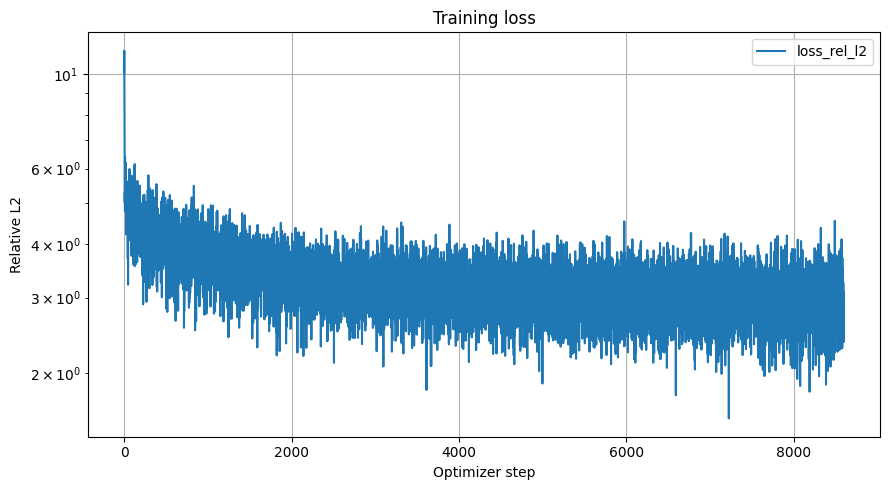

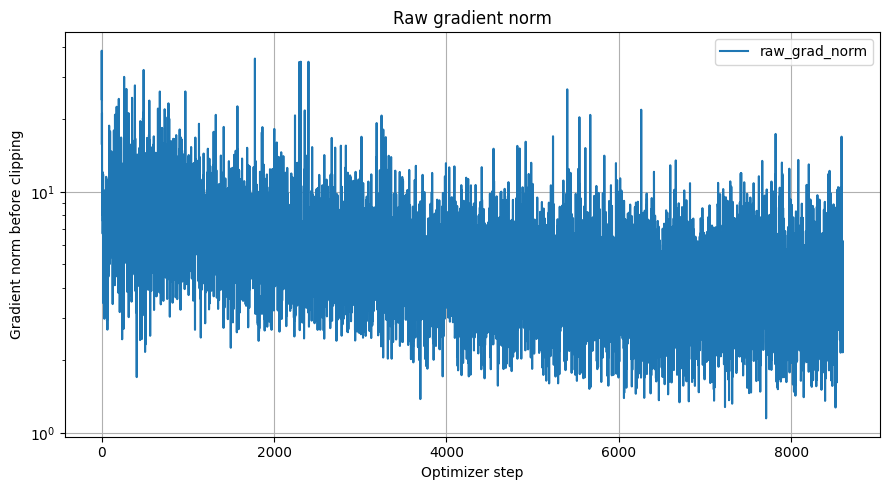

In [13]:
def plot_series(df, columns, ylabel, title, logy=False):
    if df is None or len(df) == 0:
        print("No data for:", title)
        return

    plt.figure(figsize=(9, 5))

    for col in columns:
        if col in df.columns:
            plt.plot(
                df["global_optimizer_step"],
                df[col],
                label=col,
            )

    plt.xlabel("Optimizer step")
    plt.ylabel(ylabel)
    plt.title(title)

    if logy:
        plt.yscale("log")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


if len(step_log):
    step_df = pd.DataFrame(step_log)

    plot_series(
        step_df,
        ["loss_rel_l2"],
        "Relative L2",
        "Training loss",
        logy=True,
    )

    plot_series(
        step_df,
        ["raw_grad_norm"],
        "Gradient norm before clipping",
        "Raw gradient norm",
        logy=True,
    )



## 12. Gradients and parameter values

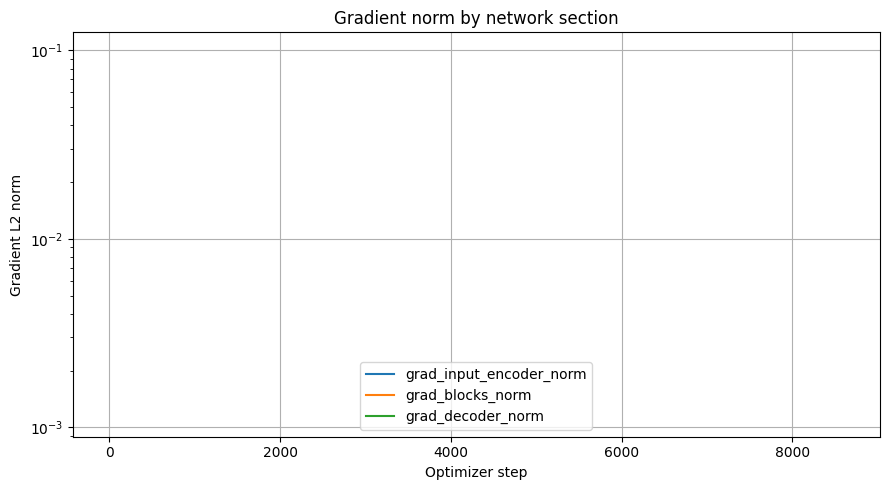

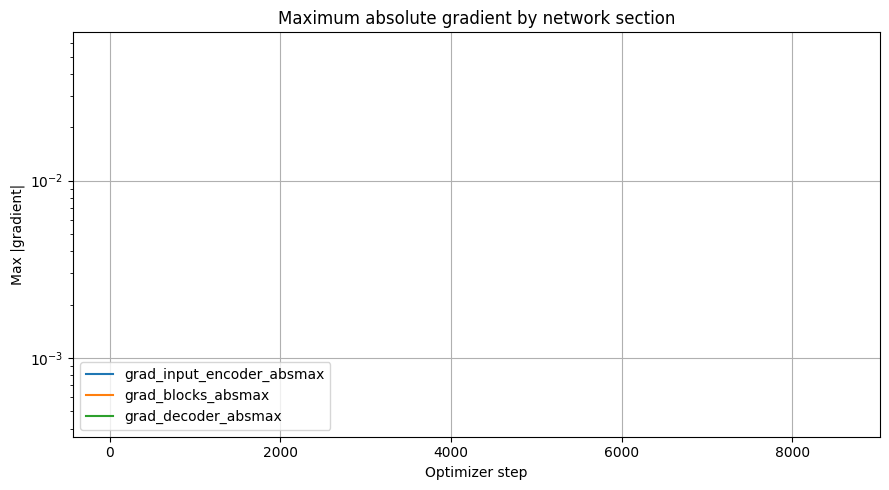

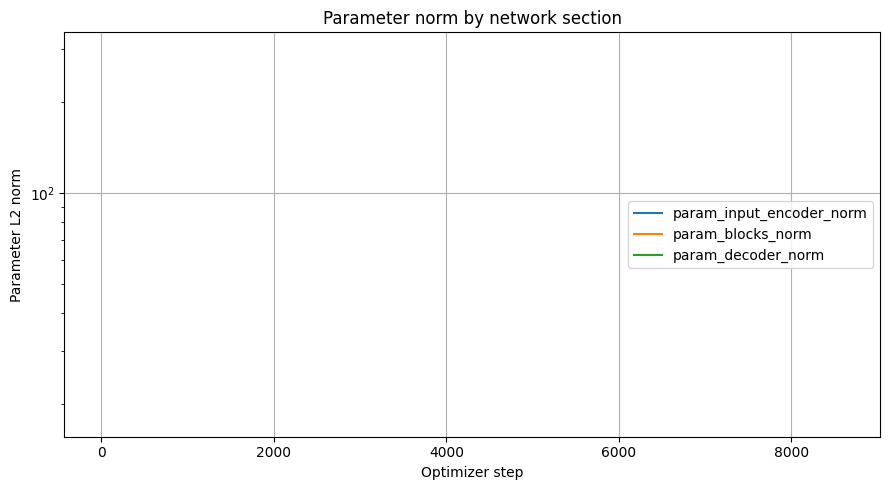

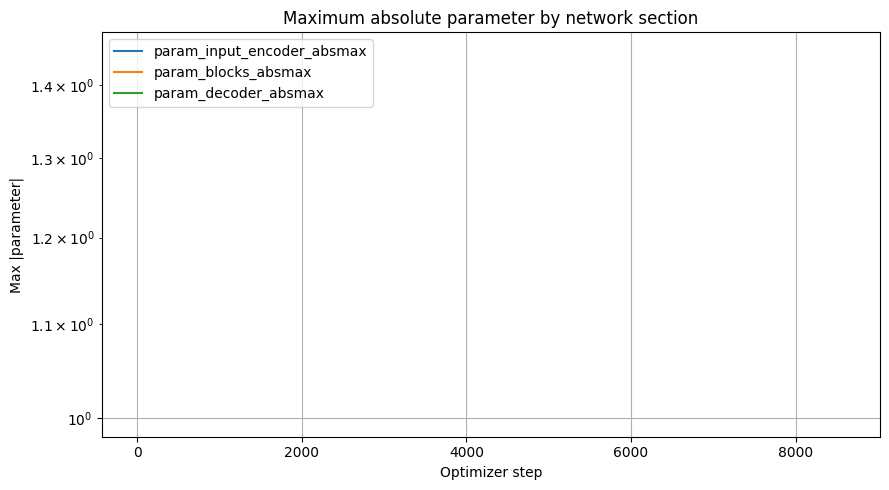

In [14]:
if len(step_log):
    # Gradient norms
    plot_series(
        step_df,
        [
            "grad_input_encoder_norm",
            "grad_blocks_norm",
            "grad_decoder_norm",
        ],
        "Gradient L2 norm",
        "Gradient norm by network section",
        logy=True,
    )

    # Gradient maximums
    plot_series(
        step_df,
        [
            "grad_input_encoder_absmax",
            "grad_blocks_absmax",
            "grad_decoder_absmax",
        ],
        "Max |gradient|",
        "Maximum absolute gradient by network section",
        logy=True,
    )

    # Parameter norms
    plot_series(
        step_df,
        [
            "param_input_encoder_norm",
            "param_blocks_norm",
            "param_decoder_norm",
        ],
        "Parameter L2 norm",
        "Parameter norm by network section",
        logy=True,
    )

    # Parameter maximums
    plot_series(
        step_df,
        [
            "param_input_encoder_absmax",
            "param_blocks_absmax",
            "param_decoder_absmax",
        ],
        "Max |parameter|",
        "Maximum absolute parameter by network section",
        logy=True,
    )

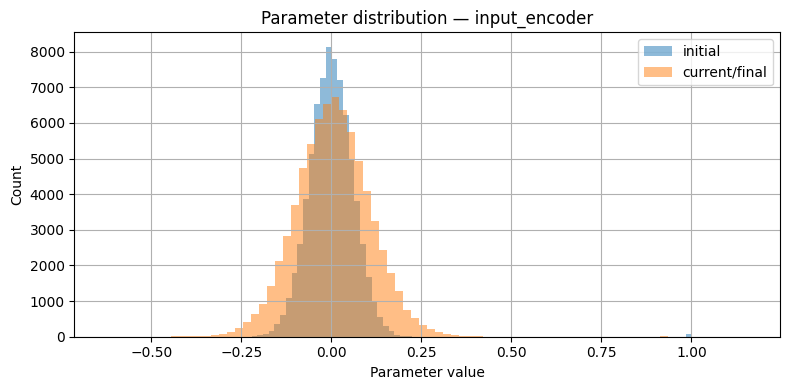

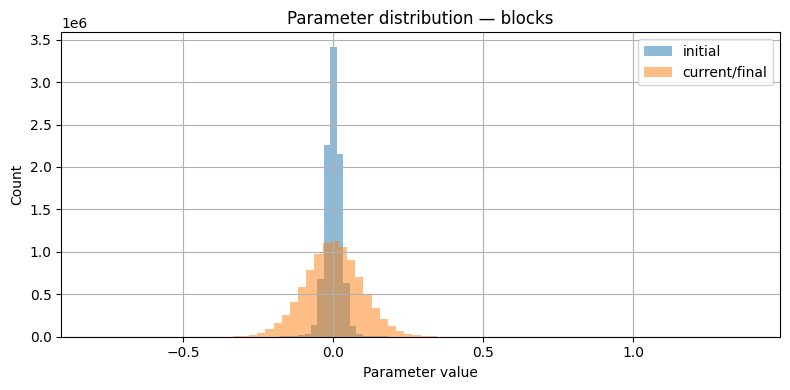

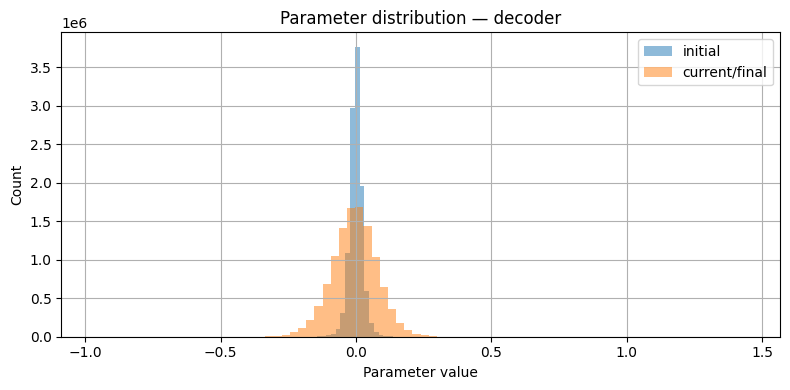

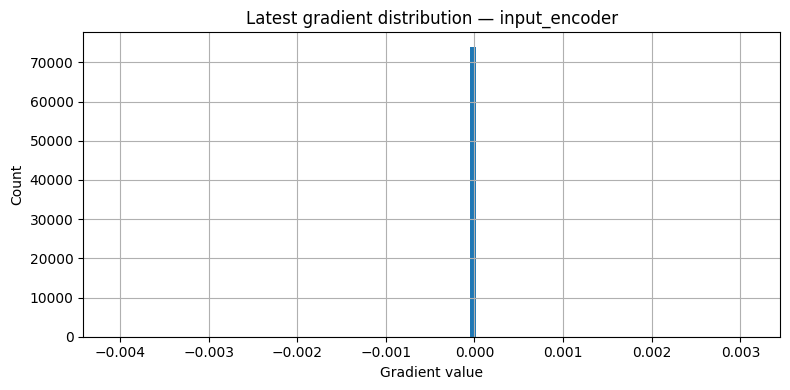

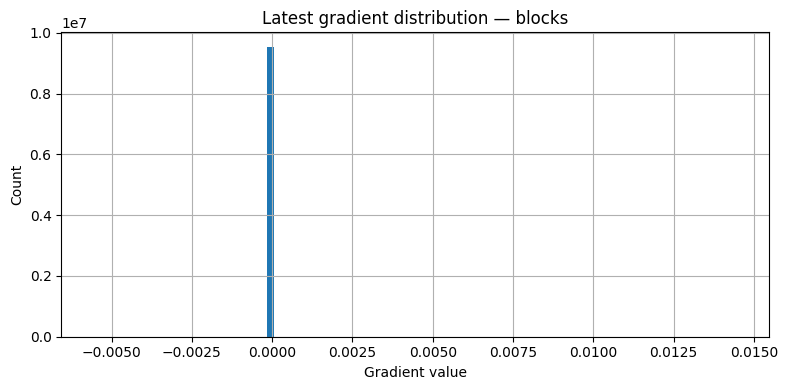

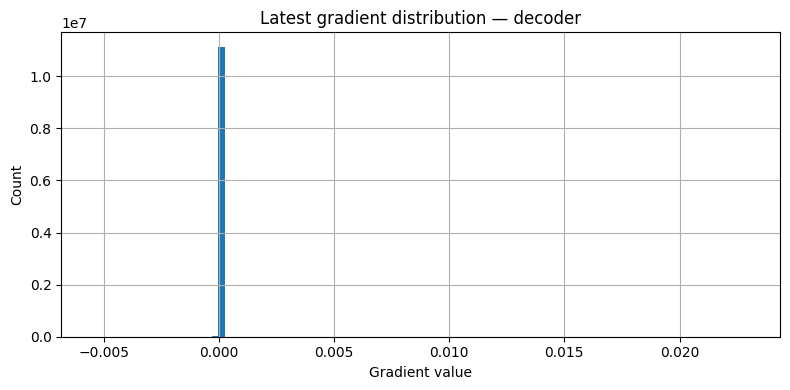

In [15]:
final_parameter_snapshot = snapshot_parameter_values(model)

for group_name, final_values in final_parameter_snapshot.items():
    initial_values = initial_parameter_snapshot.get(
        group_name,
        np.array([]),
    )

    plt.figure(figsize=(8, 4))

    if len(initial_values):
        plt.hist(
            initial_values,
            bins=80,
            alpha=0.5,
            label="initial",
        )

    if len(final_values):
        plt.hist(
            final_values,
            bins=80,
            alpha=0.5,
            label="current/final",
        )

    plt.xlabel("Parameter value")
    plt.ylabel("Count")
    plt.title(f"Parameter distribution — {group_name}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


if last_gradient_snapshot is not None:
    for group_name, values in last_gradient_snapshot.items():
        if len(values) == 0:
            continue

        plt.figure(figsize=(8, 4))
        plt.hist(values, bins=100)
        plt.xlabel("Gradient value")
        plt.ylabel("Count")
        plt.title(f"Latest gradient distribution — {group_name}")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

## 13. U-Net encoder and decoder internals

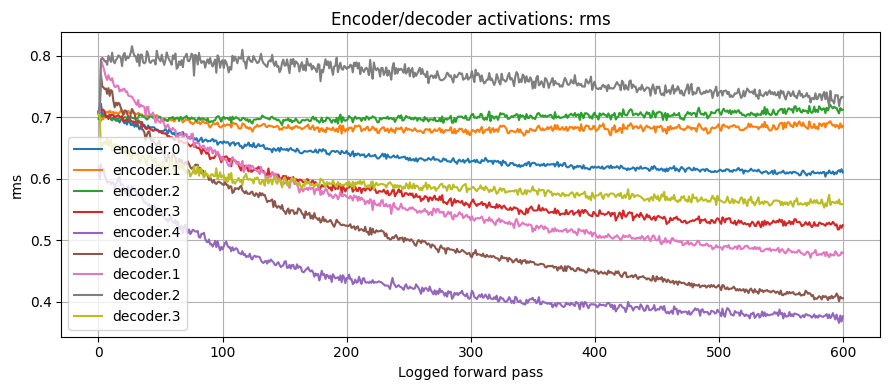

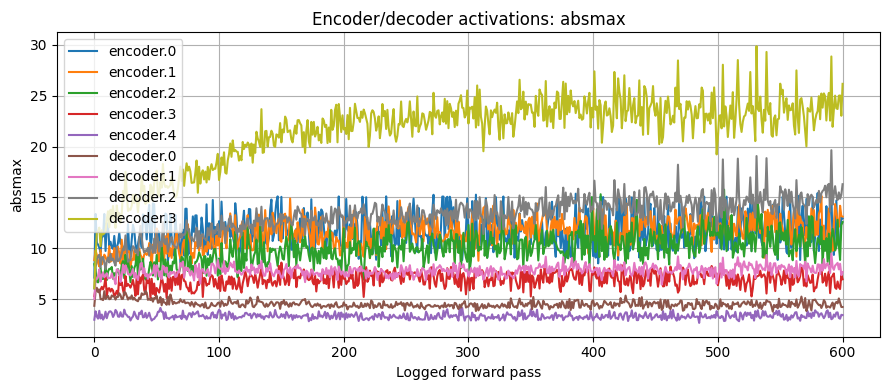

In [16]:
internal_df = recorder.dataframe()
if len(internal_df):
    tensor_df = internal_df[internal_df["kind"] == "tensor"].copy()
    for metric in ("rms", "absmax"):
        plt.figure(figsize=(9, 4))
        for tag in tensor_df["tag"].unique():
            d = tensor_df[tensor_df["tag"] == tag].reset_index(drop=True)
            plt.plot(np.arange(len(d)), d[metric], label=tag)
        plt.xlabel("Logged forward pass"); plt.ylabel(metric)
        plt.title("Encoder/decoder activations: " + metric)
        plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()
else:
    print("No detailed internal records.")


## 14. Layer output evolution

,epoch,batch,tag,mean,std,rms,absmax,norm
5400,200,40,encoder.0,0.347886,0.501513,0.610361,12.936135,1767.793213
5401,200,40,encoder.1,0.329646,0.601341,0.685768,13.111303,1404.452148
5402,200,40,encoder.2,0.338052,0.626979,0.712308,12.571296,1031.531494
5403,200,40,encoder.3,0.227987,0.472124,0.524290,6.948989,536.872620
5404,200,40,encoder.4,0.197157,0.320283,0.376102,3.425721,192.563995
5405,200,40,decoder.0,0.180452,0.363251,0.405603,4.220194,415.337891
5406,200,40,decoder.1,0.194053,0.437949,0.479015,7.653886,693.688477
5407,200,40,decoder.2,0.267832,0.681705,0.732432,16.297045,1500.020508
5408,200,40,decoder.3,0.189483,0.525370,0.558496,26.167194,1617.575806


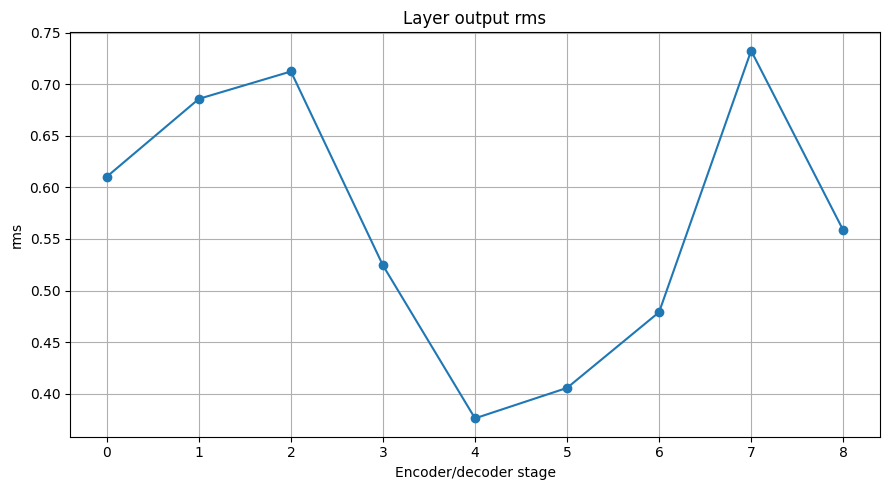

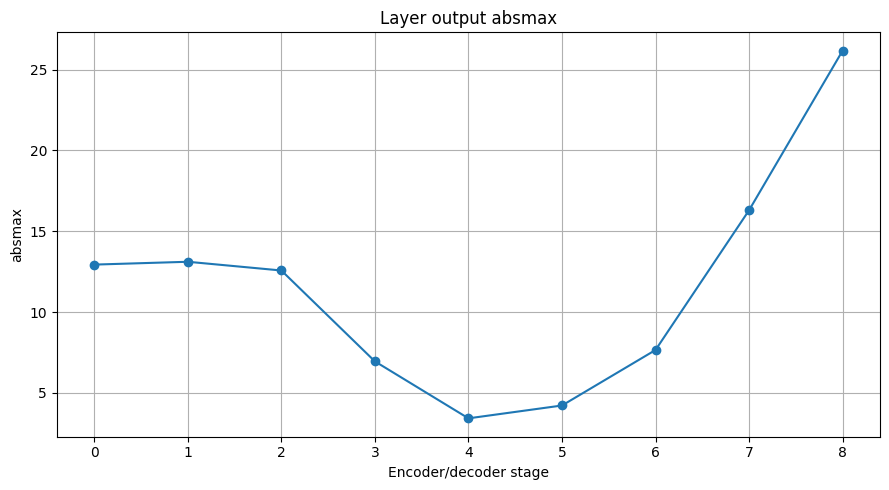

In [17]:
internal_df = recorder.dataframe()
tensor_df = internal_df[internal_df["kind"] == "tensor"].copy()
if len(tensor_df):
    latest_epoch = tensor_df["epoch"].max()
    d = tensor_df[tensor_df["epoch"] == latest_epoch]
    d = d[d["batch"] == d["batch"].max()]
    display(d[["epoch", "batch", "tag", "mean", "std", "rms", "absmax", "norm"]])
    for metric in ("rms", "absmax"):
        plt.figure(figsize=(9, 5))
        plt.plot(np.arange(len(d)), d[metric], marker="o")
        plt.xlabel("Encoder/decoder stage"); plt.ylabel(metric)
        plt.title("Layer output " + metric); plt.grid(True); plt.tight_layout(); plt.show()

## 15. Epoch curves

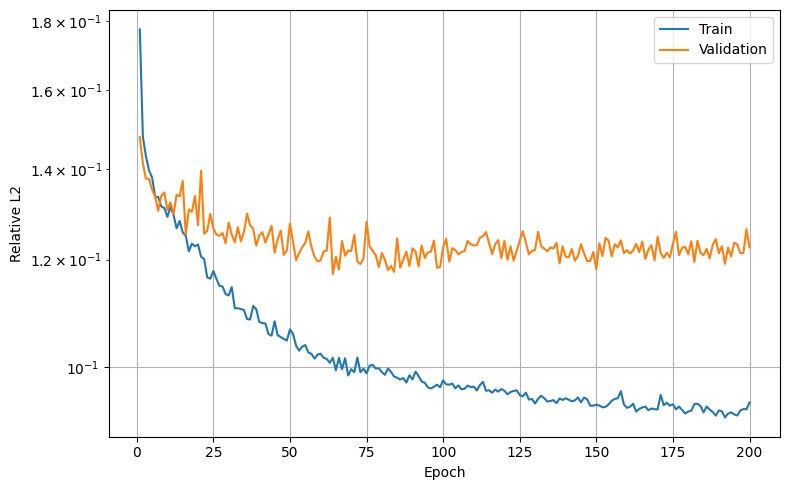

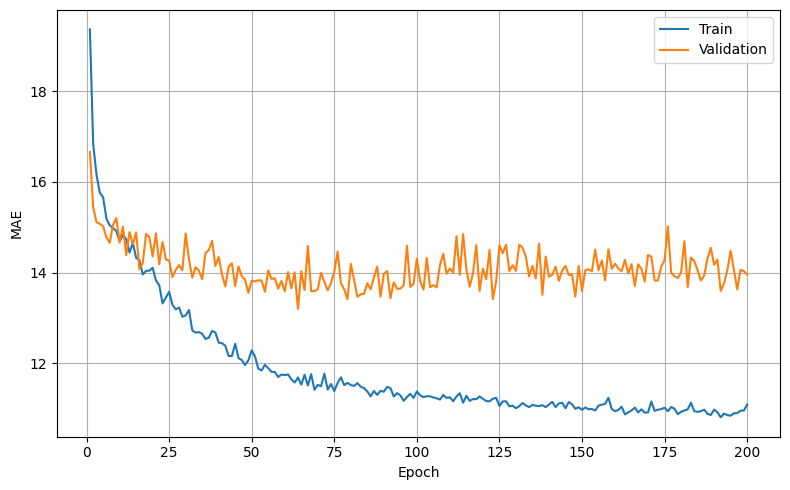

In [18]:
if len(history["train_rel_l2"]):
    e = np.arange(1, len(history["train_rel_l2"]) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(e, history["train_rel_l2"], label="Train")
    plt.plot(e, history["val_rel_l2"], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Relative L2")
    plt.yscale("log")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(e, history["train_mae"], label="Train")
    plt.plot(e, history["val_mae"], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("MAE")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("No complete epoch recorded.")

## 16. Interpretation

This experiment tests whether the local 64x64 inputs uniquely determine temperature. Within each verified pair, geometry and cooling match globally and all eight local model channels match exactly, but external power differs. No temperature-difference threshold or label ranking is used for subset selection. The power settings can change multiple chips; the manifests list changed positive instance IDs and changed pixels labelled as background. This is a device-group intervention, not a claim of independently controlling one chip.

The first sections build the subset, export the exact simulation paths/conditions/patch positions, and summarize all pairs with three detailed plot previews. We target 1,000 verified pairs, taking up to three operating-condition pairs per layout, with no layout-search cap. One pair is taken from each geometry before second/third pairs. A seeded 80/20 split separates training and validation geometries; every condition pair and simulation for a geometry stays together. Only original TrainData is used. This controlled split is for an information-sufficiency investigation, not a benchmark estimate of generalization.

The network sees ONLY the fixed matched 64x64 patches. Targets are both original simulated temperature fields, never synthesized from edited power maps. No global power scalars, case identifiers or layout IDs are added to the model. There is no random patch sampling, augmentation or sliding-window context in this experiment. The full-image and sliding-window training notebooks are unchanged.

Every deterministic local model must return the same prediction for both identical inputs. If the temperature targets differ, perfect prediction of both is impossible. For a pair with targets A and B, the worst of its two RelL2 errors is at least `||A-B||_2 / (||A||_2 + ||B||_2)`, by the triangle inequality. This bound is a mathematical constraint, not a learned-model result. The target-to-target RelL2 uses A as reference and is a different quantity.

Epoch Mean/Max/Median/P90/P95/P99 are dimensionless per-patch RelL2 values, computed on decoded temperature fields. MAE retains units of Celsius. Normalization is fitted only on the training layouts' original full fields and cached. Held-out test data is not used. A positive target difference is a counterexample; a zero difference does not prove global sufficiency.

External architecture: `nnunetv2==2.7.0` and `dynamic-network-architectures==0.4.3`, with the same diagnostic layout as the existing notebook. Sources: [nnU-Net](https://github.com/MIC-DKFZ/nnUNet) and [Multi-topology Dataset](https://github.com/henkuailederen/Multi-topology-Dataset). The data are CC BY 4.0; cite the repository and accompanying study by Ruiting Ke, Jianfeng Tao and Chengliang Liu. Cite Isensee et al., Nature Methods (2021), for nnU-Net.


The 1000-pair output directory preserves earlier runs. Repeated simulation patches are deduplicated for training/validation and normalization uses unique training files. Epoch statistics cover unique patches; the final comparison CSV covers all 1,000 pairs. Summary plots cover every selected pair; detailed input/target and prediction plots are limited to inspect_pairs to keep the notebook manageable. All pairs still participate in fitting or validation and in the final metrics CSV.


**Previous narrow residual baseline:** architecture=resenc used the official ResidualEncoderUNet with the same five stages, channels [32,64,128,256,320], downsampling strides and two-convolution decoder as the plain baseline. Each encoder stage uses one two-convolution residual block; the upstream residual encoder also includes its stem and projection paths, so the exact parameter count changes slightly. This is not the much deeper [1,3,4,6,6] ResEnc preset. The data, split, input channels, training budget, zero weight decay and metrics are unchanged. Checkpoints contain architecture settings. Residual outputs go to a separate directory; the plain baseline checkpoints remain intact. Other notebooks continue to default to the plain architecture.


**Wider residual comparison:** channels are now [64,128,256,512,512], keeping five stages, one two-convolution residual block per encoder stage, the same decoder depth, 64x64 inputs, matched subset, split, optimizer, learning rate and epoch budget. Outputs go to patch_context_investigation_1000pairs_resenc_wide. The earlier plain and narrow residual checkpoints remain in their existing folders. This run changes width rather than adding more residual blocks.


## 17. Best checkpoint — compare identical predictions against both simulated targets

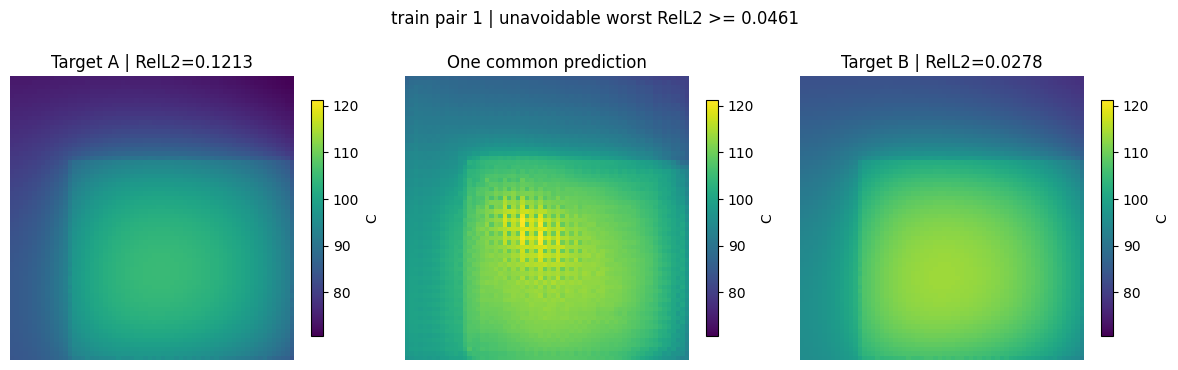

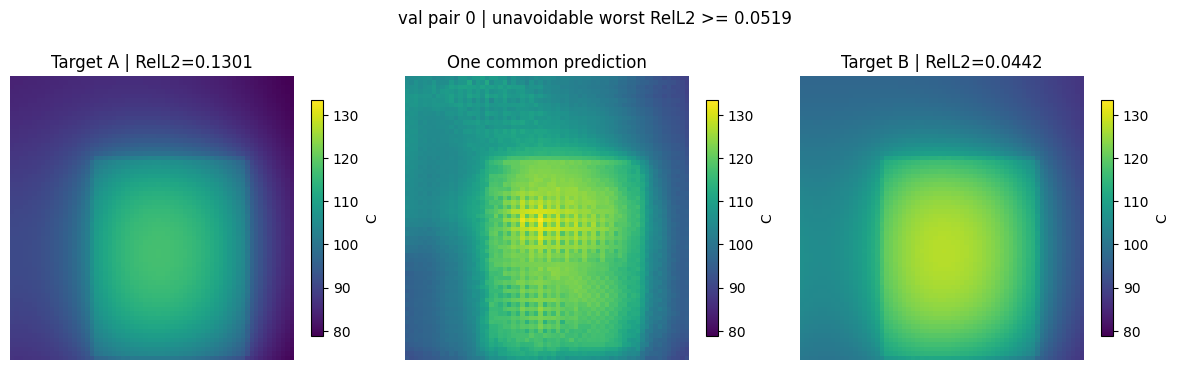

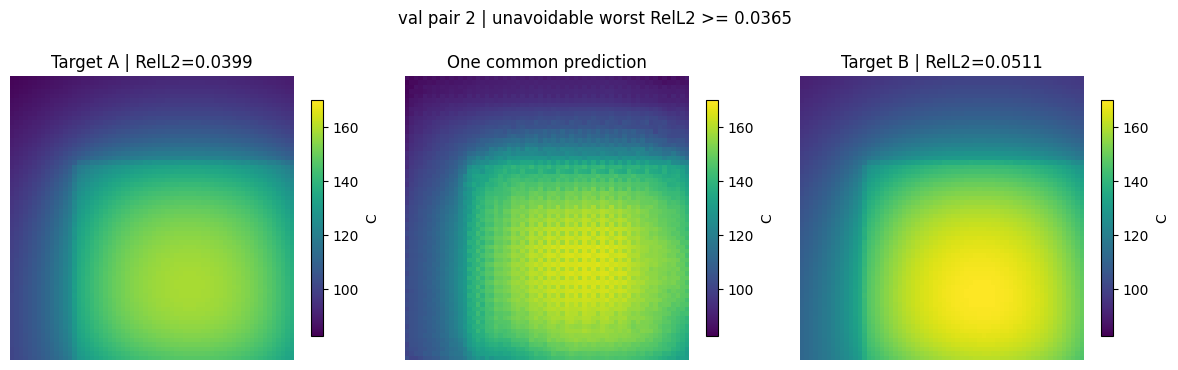

,pair_id,subset,rel_l2_a,rel_l2_b,worst_rel_l2,theoretical_lower_bound,identical_inputs,prediction_difference_rel_l2
0,1,train,0.121286,0.027804,0.121286,0.046085,True,0.0
1,3,train,0.102513,0.014589,0.102513,0.044576,True,0.0
2,4,train,0.086582,0.134701,0.134701,0.112080,True,0.0
3,5,train,0.052796,0.057805,0.057805,0.049132,True,0.0
4,6,train,0.068609,0.112807,0.112807,0.090163,True,0.0
...,...,...,...,...,...,...,...,...
995,972,val,0.125071,0.175765,0.175765,0.151763,True,0.0
996,980,val,0.158415,0.230944,0.230944,0.062606,True,0.0
997,992,val,0.090221,0.182183,0.182183,0.053853,True,0.0
998,995,val,0.082042,0.125206,0.125206,0.026405,True,0.0


Best epoch: 64
Checkpoint: pcb\outputs\patch_context_investigation_1000pairs_resenc_wide\patch_context.pt
Held-out benchmark testing remains disabled.


In [19]:
checkpoint = torch.load(HPARAMS["checkpoint_path"], map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
normalizer = NormalizationStats(**checkpoint["normalization"])
model.eval()
comparison_rows = []
for subset, dataset in (("train", train_dataset), ("val", val_dataset)):
    for index, record in enumerate(dataset.records):
        sample_a, sample_b = dataset.pair_indices[index]
        image_a, target_a_norm = dataset[sample_a]
        image_b, target_b_norm = dataset[sample_b]
        assert torch.equal(image_a, image_b)
        with torch.no_grad():
            predictions = normalizer.decode_temperature(predict_field(torch.stack([image_a, image_b])))
        targets = normalizer.decode_temperature(torch.stack([target_a_norm, target_b_norm]))
        torch.testing.assert_close(predictions[0], predictions[1], rtol=1e-6, atol=1e-5)
        errors = relative_l2_per_sample(predictions, targets)
        bound = record["unavoidable_worst_case_rel_l2"]
        assert errors.max().item() + 1e-5 >= bound
        comparison_rows.append(dict(pair_id=record["pair_id"], subset=subset,
                                    rel_l2_a=errors[0].item(), rel_l2_b=errors[1].item(),
                                    worst_rel_l2=errors.max().item(), theoretical_lower_bound=bound,
                                    identical_inputs=True,
                                    prediction_difference_rel_l2=relative_l2_per_sample(
                                        predictions[:1], predictions[1:]).item()))
        if record["pair_id"] in preview_pair_ids:
            fig, axes = plt.subplots(1, 3, figsize=(12, 4))
            arrays = [targets[0, 0].numpy(), predictions[0, 0].numpy(), targets[1, 0].numpy()]
            lo, hi = min(a.min() for a in arrays), max(a.max() for a in arrays)
            titles = [f"Target A | RelL2={errors[0]:.4f}", "One common prediction", f"Target B | RelL2={errors[1]:.4f}"]
            for ax, array, title in zip(axes, arrays, titles):
                im = ax.imshow(array, vmin=lo, vmax=hi); ax.set_title(title); ax.axis("off")
                fig.colorbar(im, ax=ax, shrink=.7, label="C")
            fig.suptitle(f"{subset} pair {record['pair_id']} | unavoidable worst RelL2 >= {bound:.4f}")
            fig.tight_layout(); fig.savefig(WORKING_DIR / f"prediction_pair_{record['pair_id']:02d}.png", dpi=130)
            plt.show(); plt.close(fig)
comparisons = pd.DataFrame(comparison_rows)
comparisons.to_csv(WORKING_DIR / "paired_prediction_metrics.csv", index=False)
display(comparisons)
print("Best epoch:", checkpoint["epoch"])
print("Checkpoint:", HPARAMS["checkpoint_path"])
print("Held-out benchmark testing remains disabled.")
for handle in hook_handles:
    handle.remove()
